# Predicting Goodreads Shelves from Book Descriptions

*CSE 258, Assignment 2*

**Abstract.** Goodreads readers assign books to user-defined shelves that act as genre tags, but a newly published book has no shelves, which leaves shelf-based recommendation without input for new items. We study whether the description of a romance novel is sufficient to predict 15 common reader shelves. Using 299,789 books from the UCSD Goodreads dataset, we train one logistic regression per shelf on TF-IDF word and character features and evaluate it on 60,410 held-out books. The model reaches a macro-F1 of 0.454, compared with 0.106 for a keyword baseline. Performance varies widely across shelves, from an F1 of 0.812 for `manga` to 0.244 for `contemporary`. Across shelves, F1 is strongly correlated with a measure of reader disagreement about the label (Spearman $\rho = -0.82$) and only weakly with the number of training examples ($\rho = +0.23$). We conclude that descriptions predict shelves with a distinctive vocabulary well, and that the main limit on the remaining shelves is the consistency of the labels.

## I. Introduction

Goodreads users organize books into shelves that they name themselves. Shelves such as `historical-romance`, `paranormal`, and `m-m` function as community-assigned genre tags, and recommendation and search systems can use them to retrieve books of a given kind. Shelves accumulate only after readers have engaged with a book, so a newly published book has none. This is an instance of the item cold-start problem.

A new book does have a description, usually supplied by the publisher. This report addresses the following question: given only its description, can a model predict which shelves readers will assign to a book? We study the question with a TF-IDF representation and a linear classifier, a standard approach to text classification [3].

Sections II to VI follow the five parts of the assignment. Section II defines the predictive task and the evaluation protocol. Section III describes the dataset, its exploratory analysis, and the construction of labels. Section IV presents the model. Section V reports the evaluation. Section VI discusses related work, and Section VII concludes.

## II. Predictive Task

### A. Problem Formulation

Each example is one book. The input is the text of its description, and the output is a vector of 15 binary labels, one for each of the 15 most frequent genre shelves. A book may carry several of these shelves or none, so the task is multi-label classification.

The labels are derived from reader behavior. For every book, the dataset lists its most popular shelves together with the number of times readers placed the book on each. A shelf is considered a true label for a book when it receives at least 10% of the book's genre-related shelf votes (Section III-C). This definition assumes that a shelf chosen by a tenth of a book's readers reflects a shared judgment about the book, whereas a shelf chosen by one or two readers does not.

### B. Cold-Start Approximation

The dataset is a single snapshot and does not record books at the time of release. We therefore approximate the cold-start setting by hiding the shelves of books whose shelves are known and predicting them from the description alone. The approximation assumes that the descriptions of established books are representative of those of new books. It also restricts the study to books with at least 10 genre votes, which are more established than a typical new release.

### C. Evaluation Protocol

The books were split into training (64%), validation (16%), and test (20%) sets. Editions of the same work usually share a description, so the split was performed by work, and all editions of a book belong to the same set. Without this grouping, the model could be evaluated on descriptions it had already seen during training. The validation set was used only to select a decision threshold for each shelf, and the test set was used once, after all choices had been fixed.

Performance is measured primarily by F1, the harmonic mean of precision (the fraction of predicted shelves that are correct) and recall (the fraction of true shelves that are predicted). Micro-F1 pools all book-shelf decisions and is dominated by frequent shelves; macro-F1 averages the per-shelf F1 and weights every shelf equally. Macro-F1 is the primary metric, since the research question concerns individual shelves, including rare ones. ROC AUC and average precision (AP) are also reported; both measure the quality of the ranking before a threshold is applied. Accuracy is not reported. Because 97.1% of book-shelf pairs are negative, a model that never predicts a shelf would attain 97.1% accuracy while being of no use.

### D. Baselines

Three baselines involve no learning. The label-prior baseline predicts a shelf whenever more than half of the training books carry it. No shelf is that frequent, so this baseline predicts nothing and attains an F1 of zero, which is the floor any useful model must exceed. The every-shelf baseline predicts all 15 shelves for every book; it attains a recall of 1, and its F1 on a shelf with positive rate $p$ is $2p/(1+p)$, so it shows the score obtainable without reading the text. The keyword baseline predicts a shelf whenever the shelf name, for example "historical romance", occurs in the description, and tests whether the task can be solved by matching the obvious term. The proposed model is additionally evaluated with the default threshold of probability 0.5, which separates the contribution of the learned weights from that of threshold selection.

### E. Validity

The validity of the predictions is assessed in three ways. First, the split guarantees that test books, and all other editions of them, play no part in training or threshold selection. Second, the learned weights are inspected to confirm that the model relies on genre-related terms. Third, because shelf votes are a noisy proxy for genre, the label noise of each shelf is quantified (Section III-D) and related to the model's performance (Section V-C).

## III. Data

### A. Dataset

We use the romance subset of the UCSD Goodreads dataset [1], [2], which was collected in late 2017 by crawling public Goodreads shelves. Each record describes one book: its title, authors, description, publication details, rating summary, similar books, and most popular shelves with their vote counts. The file contains neither user identifiers nor reviews, so interaction-based models such as latent factor models and Bayesian personalized ranking cannot be applied, and a content-based approach is required. The dataset is distributed for academic use only and is not included in the repository; the notebook reads a local copy whose path is given in `secret.env`.

The code below loads the full file and summarizes each field.

In [1]:
import gzip
import json
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from dotenv import find_dotenv, load_dotenv
from scipy.sparse import csr_matrix, hstack
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit

In [2]:
load_dotenv(find_dotenv('secret.env', usecwd=True))
PATH = os.environ['GOODREADS_PATH']

In [3]:
os.makedirs('figs', exist_ok=True)
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#666666', 'axes.grid': True, 'grid.color': '#e6e6e6',
                     'axes.axisbelow': True, 'savefig.bbox': 'tight'})
GRAY = '#b3b3b3'
FOCUS = {'manga': '#257de0', 'historical-romance': '#f47230', 'contemporary': '#00b894'}


def color(shelf):
    return FOCUS.get(shelf, GRAY)


def save(n):
    plt.tight_layout()
    plt.savefig(f'figs/fig{n}.png', dpi=200)
    plt.show()

In [4]:
# set LIMIT (e.g. 50_000) for a quick pass
LIMIT = None
rows = []
with gzip.open(PATH, 'rt', encoding='utf-8') as f:
    for i, line in enumerate(f):
        if LIMIT and i >= LIMIT:
            break
        rows.append(json.loads(line))
df = pd.DataFrame(rows)
del rows
print(df.shape)

(335449, 29)


In [5]:
df.iloc[0].astype(str).str.slice(0, 80)

isbn                                                                     
text_reviews_count                                                      4
series                                                                 []
country_code                                                           US
language_code                                                            
popular_shelves         [{'count': '4', 'name': 'to-read'}, {'count': ...
asin                                                                     
is_ebook                                                             true
average_rating                                                       3.86
kindle_asin                                                              
similar_books                                                          []
description             Secrets. Sometimes keeping them in confidence ...
format                                                              ebook
link                    https://www.go

In [6]:
empty = df.map(lambda v: v in ('', None) or (isinstance(v, list) and not v))
(1 - empty.mean()).sort_values().round(3)

edition_information     0.101
asin                    0.366
isbn                    0.394
isbn13                  0.504
kindle_asin             0.534
num_pages               0.593
publication_day         0.605
similar_books           0.619
series                  0.623
publisher               0.631
publication_month       0.659
format                  0.664
language_code           0.689
publication_year        0.697
description             0.909
popular_shelves         1.000
authors                 1.000
link                    1.000
average_rating          1.000
is_ebook                1.000
country_code            1.000
text_reviews_count      1.000
url                     1.000
image_url               1.000
book_id                 1.000
ratings_count           1.000
work_id                 1.000
title                   1.000
title_without_series    1.000
dtype: float64

In [7]:
for c in ['average_rating', 'ratings_count', 'text_reviews_count', 'num_pages',
          'publication_year', 'publication_month', 'publication_day']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df[['average_rating', 'ratings_count', 'text_reviews_count', 'num_pages', 'publication_year']].describe()

,average_rating,ratings_count,text_reviews_count,num_pages,publication_year
count,335449.000000,3.354490e+05,335449.000000,198819.000000,233649.000000
mean,3.880701,4.480081e+02,37.945822,267.380552,2012.429302
std,0.376427,7.285129e+03,277.039372,311.701089,249.421360
min,0.000000,0.000000e+00,0.000000,0.000000,1.000000
25%,3.670000,1.600000e+01,3.000000,184.000000,2010.000000
50%,3.910000,5.200000e+01,9.000000,264.000000,2013.000000
75%,4.140000,1.750000e+02,25.000000,352.000000,2015.000000
max,5.000000,2.078406e+06,67203.000000,82000.000000,65535.000000


In [8]:
df['average_rating'].round(1).value_counts().sort_index()

average_rating
0.0       46
1.0       19
1.2        1
1.3        4
1.4        2
1.5        4
1.6        8
1.7       15
1.8       29
1.9       12
2.0       84
2.1       47
2.2      126
2.3      145
2.4      233
2.5      338
2.6      567
2.7      716
2.8     1349
2.9     1644
3.0     3093
3.1     3662
3.2     6741
3.3     7939
3.4    13722
3.5    14976
3.6    25643
3.7    26742
3.8    40055
3.9    34015
4.0    40837
4.1    32151
4.2    32107
4.3    19324
4.4    14607
4.5     6707
4.6     4582
4.7     1725
4.8      846
4.9      257
5.0      329
Name: count, dtype: int64

In [9]:
zero_share = (df['ratings_count'] == 0).mean()
print(f'{zero_share} share with 0 ratings')
df['ratings_count'].quantile([.1, .25, .5, .75, .9, .99])

0.004468637557423036 share with 0 ratings


0.10       5.00
0.25      16.00
0.50      52.00
0.75     175.00
0.90     591.00
0.99    5763.52
Name: ratings_count, dtype: float64

In [10]:
df[['average_rating', 'ratings_count', 'text_reviews_count', 'num_pages', 'publication_year']].corr(method='spearman')

,average_rating,ratings_count,text_reviews_count,num_pages,publication_year
average_rating,1.000000,0.088114,0.147278,0.241289,0.303357
ratings_count,0.088114,1.000000,0.848879,0.046207,-0.101965
text_reviews_count,0.147278,0.848879,1.000000,0.038564,0.142427
num_pages,0.241289,0.046207,0.038564,1.000000,-0.043116
publication_year,0.303357,-0.101965,0.142427,-0.043116,1.000000


In [11]:
df['publication_year'].value_counts().sort_index().tail(40)

publication_year
2015.0     25616
2016.0     21587
2017.0     13612
2018.0       182
2019.0        11
2020.0         1
2035.0         1
2099.0         2
2100.0         1
2102.0         2
2103.0         3
2104.0         6
2105.0         9
2106.0         4
2107.0         2
2112.0         2
2140.0         1
2616.0         1
2914.0         1
2916.0         2
2997.0         1
3016.0         1
3017.0         1
8017.0         1
20015.0        1
20017.0        1
20032.0        1
20102.0        1
20112.0        3
20113.0        1
20115.0        2
20131.0        1
20140.0        1
20141.0        1
21012.0        1
21014.0        1
21016.0        1
22012.0        1
22013.0        1
65535.0        2
Name: count, dtype: int64

In [12]:
for c in ['language_code', 'format', 'is_ebook', 'country_code']:
    print(df[c].replace('', '(empty)').value_counts().head(10), '\n')

language_code
eng        160125
(empty)    104396
en-US       18932
en-GB       14793
ita          5292
spa          5060
ind          4178
en-CA        3420
ger          3158
fre          3071
Name: count, dtype: int64 

format
(empty)                  112865
Paperback                 86188
ebook                     63500
Kindle Edition            39504
Mass Market Paperback     11924
Hardcover                  9648
Audio CD                   3573
Audible Audio              3071
Audiobook                  2213
Audio                       686
Name: count, dtype: int64 

is_ebook
true     194447
false    141002
Name: count, dtype: int64 

country_code
US    335449
Name: count, dtype: int64 



In [13]:
for c in ['authors', 'series', 'similar_books', 'popular_shelves']:
    print(c, df[c].map(len).describe()[['mean', '50%', 'max']].round(1).to_dict())

authors {'mean': 1.2, '50%': 1.0, 'max': 51.0}
series {'mean': 0.7, '50%': 1.0, 'max': 4.0}
similar_books {'mean': 9.4, '50%': 13.0, 'max': 18.0}
popular_shelves {'mean': 78.2, '50%': 100.0, 'max': 100.0}


In [14]:
tot, nb = Counter(), Counter()
for shelves in df['popular_shelves']:
    for s in shelves:
        tot[s['name']] += int(s['count'])
        nb[s['name']] += 1
pd.DataFrame({'total': tot, 'books': nb}).sort_values('total', ascending=False).head(40)

,total,books
to-read,997209055,333089
currently-reading,89012773,289536
classics,43948395,6761
favorites,39882117,189483
romance,32520924,312899
fiction,14947713,178612
books-i-own,9020178,137973
contemporary,7041696,192850
owned,6981115,187043
classic,5957605,4726


In [15]:
a = Counter(x['author_id'] for au in df['authors'] for x in au)
a_stats = pd.Series(a).describe()[['mean', '50%', 'max']].round(1).to_dict()
print(f'{len(a)} authors; books per author: {a_stats}')
s = Counter(x for se in df['series'] for x in se)
s_stats = pd.Series(s).describe()[['mean', '50%', 'max']].round(1).to_dict()
print(f'{len(s)} series; books per series: {s_stats}')

52687 authors; books per author: {'mean': 7.6, '50%': 2.0, 'max': 2417.0}
116535 series; books per series: {'mean': 1.9, '50%': 1.0, 'max': 114.0}


In [16]:
d = df['description'].replace('', pd.NA).dropna()
n_words = d.str.split().str.len()
d_words = n_words.describe()[['mean', '50%', 'max']].round(0).to_dict()
print(f'{len(d)} with description; words: {d_words}')
d.iloc[:3].tolist()

304837 with description; words: {'mean': 156.0, '50%': 147.0, 'max': 3943.0}


["Secrets. Sometimes keeping them in confidence is a good thing. Other times secrets can slowly allow a woman's soul to rot.\nWhitney Beaupre has been hiding a big secret for years, one that's beginning to wear her down both on and off the ice. Pretending to be something she's not is exhausting. Wanting to be free but afraid to break out of her prison is terrifying. Seeking love but then hiding from it is crushing to the spirit, yet Whitney feels compelled to keep living the lie. Until the night Hannah Kym appears in her life. Whitney's attraction to Hannah is deep, fierce, and instantaneous. The Temple art major is everything Whitney has dreamed of and more. But those old fears keep clawing at the Venom center, keeping her locked in the closet despite the passion and affection she feels for Hannah.\nCan love finally break the shackles holding Whitney's heart and soul captive?",
 "The funny and heartwarming story of a young lady whose zeal, snobbishness, and self-satisfaction lead to s

In [17]:
ids = set(df['book_id'])
sim = [x for lst in df['similar_books'] for x in lst]
inside = sum(x in ids for x in sim) / max(len(sim), 1)
print(f'{len(sim)} links; {inside:.3f} point inside the file')

3146805 links; 0.838 point inside the file


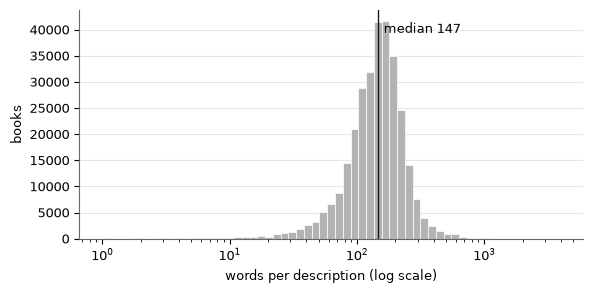

In [18]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(n_words, bins=np.logspace(0, np.log10(n_words.max()), 60), color=GRAY, edgecolor='white', linewidth=0.5)
ax.axvline(n_words.median(), color='#191919', linewidth=1)
ax.annotate(f'median {n_words.median():.0f}', (n_words.median(), ax.get_ylim()[1] * 0.9), xytext=(4, 0),
            textcoords='offset points')
ax.set(xscale='log', xlabel='words per description (log scale)', ylabel='books')
ax.grid(axis='x', visible=False)
save(1)

*Fig. 1. Distribution of description length over the books with a description, in words, on a logarithmic axis. The vertical line marks the median.*

### B. Exploratory Analysis

The file contains 335,449 books, of which 90.9% have a non-empty description. The median description length is 147 words, and most descriptions are a paragraph or longer (Fig. 1).

The remaining metadata is noisy. Publication year is missing for 30% of books and includes invalid values such as 1, 20015, and 65535, which are most likely entry errors. Rating counts are highly skewed, with a median of 52, a mean of 448, and a maximum of about 2.08 million. Language codes are missing for 31% of books, and Italian, Spanish, and Indonesian editions each number several thousand, so not all descriptions are in English. Since the model reads only the description, these fields require no cleaning; the mixture of languages, however, introduces noise into the text itself.

The shelf summary shows why the raw shelves cannot serve as labels directly. The most frequently used shelves, `to-read`, `currently-reading`, and `favorites`, record a reader's interaction with a book and carry no genre information. Genre shelves such as `historical-romance` and `paranormal` rank lower. Finally, 83.8% of `similar_books` links point to books within the file, which would support a link-prediction task; that task is outside the scope of this report.

### C. Label Construction

Labels were constructed from the raw shelf votes in four steps. First, shelves that do not describe content were removed: reading status (`to-read`), format (`kindle`, `ebook`), ownership (`owned`), and the tags `romance` and `fiction`, which nearly every book in the file carries and which therefore cannot distinguish books from one another. These shelves form the set `EXCLUDE`, and the remaining votes are referred to as content votes. Second, only books with at least 10 content votes were retained, since with fewer votes a label could be determined by two or three readers. Third, a shelf was taken as a positive label for a book when it received at least 10% of the book's content votes. Fourth, the 15 shelves most often positive among the training books were selected as the label set; selecting them from the training data alone keeps the test set unseen.

The 10% threshold trades label quality against label quantity. The sweep below shows that, with 10 required votes, a threshold of 5% gives the 15th most frequent shelf 10,511 positive books, 10% gives 3,105, and 20% gives only 376. A low threshold admits shelves chosen by only a few readers, while a high threshold leaves too few positive examples for training. The 10% threshold retains several thousand positive examples for every shelf.

In [19]:
EXCLUDE = {
    'to-read', 'currently-reading', 'read', 'favorites', 'favorite', 'favourites', 'owned', 'own',
    'my-books', 'books-i-own', 'default', 'library', 'wish-list', 'wishlist', 'to-buy',
    'ebook', 'ebooks', 'e-book', 'kindle', 'audiobook', 'audiobooks', 'dnf', 'abandoned',
    'did-not-finish', 're-read', 'romance', 'fiction',
}
MIN_VOTES = 10
MIN_FRAC = 0.10
K = 15

In [20]:
def content_shelves(shelves):
    return {s['name']: int(s['count']) for s in shelves if s['name'] not in EXCLUDE}

df['sh'] = df['popular_shelves'].map(content_shelves)
df['sh_votes'] = df['sh'].map(lambda d: sum(d.values()))
has_text = df['description'].str.strip() != ''

In [21]:
rows = []
for votes in (5, 10, 20):
    keep = df[has_text & (df['sh_votes'] >= votes)]
    for frac in (0.05, 0.10, 0.20, 0.30):
        c = Counter(n for d, v in zip(keep['sh'], keep['sh_votes']) for n, k in d.items() if k / v >= frac)
        pos = [p for _, p in c.most_common(K)]
        rows.append({'min_votes': votes, 'min_frac': frac, 'books': len(keep),
                     'positives_top1': pos[0], f'positives_top{K}': pos[-1]})
pd.DataFrame(rows)

,min_votes,min_frac,books,positives_top1,positives_top15
0,5,0.05,303901,52825,10545
1,5,0.10,303901,19952,3255
2,5,0.20,303901,9459,376
3,5,0.30,303901,3398,38
4,10,0.05,299789,52408,10511
5,10,0.10,299789,19926,3105
6,10,0.20,299789,9310,376
7,10,0.30,299789,3392,31
8,20,0.05,285743,50103,10251
9,20,0.10,285743,19812,2839


In [22]:
elig = df[has_text & (df['sh_votes'] >= MIN_VOTES)].reset_index(drop=True)
# editions of one work share a description, so they must land in the same split
valid_work = ~elig['work_id'].isin(['', '0'])
elig['group'] = np.where(valid_work, 'work:' + elig['work_id'], 'book:' + elig['book_id'])
print(f'{len(df)} raw, {has_text.sum()} with description, {len(elig)} eligible')

335449 raw, 304837 with description, 299789 eligible


In [23]:
dev, te = next(GroupShuffleSplit(test_size=0.2, random_state=0).split(elig, groups=elig['group']))
i_tr, i_va = next(GroupShuffleSplit(test_size=0.2, random_state=1).split(dev, groups=elig['group'].iloc[dev]))
tr, va = dev[i_tr], dev[i_va]
assert not set(elig['group'].iloc[tr]) & set(elig['group'].iloc[te])
print(f'{len(tr)} train, {len(va)} validation, {len(te)} test')

191692 train, 47687 validation, 60410 test


In [24]:
c = Counter(n for d, v in zip(elig['sh'].iloc[tr], elig['sh_votes'].iloc[tr]) for n, k in d.items() if k / v >= MIN_FRAC)
SHELVES = [n for n, _ in c.most_common(K)]
share = np.array([[d.get(s, 0) / v for s in SHELVES] for d, v in zip(elig['sh'], elig['sh_votes'])])
Y = (share >= MIN_FRAC).astype(np.float32)
print(f'no label: {(Y.sum(1) == 0).mean():.1%} of books; negative book-shelf pairs: {1 - Y.mean():.1%}')
rate = pd.DataFrame({'train': Y[tr].mean(0), 'validation': Y[va].mean(0), 'test': Y[te].mean(0)}, index=SHELVES)
rate.round(3)

no label: 65.6% of books; negative book-shelf pairs: 97.1%


,train,validation,test
m-m,0.068,0.064,0.064
historical-romance,0.065,0.065,0.062
paranormal,0.045,0.042,0.043
historical,0.039,0.038,0.038
contemporary-romance,0.028,0.026,0.027
paranormal-romance,0.027,0.025,0.025
contemporary,0.027,0.029,0.030
chick-lit,0.026,0.023,0.028
new-adult,0.023,0.021,0.026
young-adult,0.018,0.018,0.022


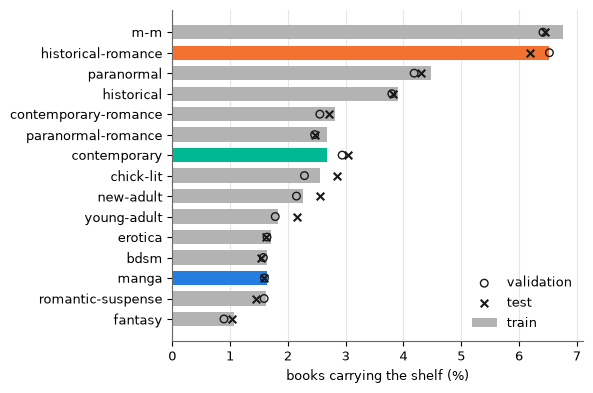

In [25]:
fig, ax = plt.subplots(figsize=(6, 4))
y = np.arange(K)
ax.barh(y, 100 * rate['train'], color=[color(s) for s in SHELVES], height=0.7, label='train')
ax.scatter(100 * rate['validation'], y, marker='o', s=30, facecolors='none', edgecolors='#191919', label='validation')
ax.scatter(100 * rate['test'], y, marker='x', s=30, color='#191919', label='test')
ax.set(yticks=y, yticklabels=SHELVES, xlabel='books carrying the shelf (%)')
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right', frameon=False)
save(2)

*Fig. 2. Percentage of books that carry each shelf, in the training set (bars), validation set (circles), and test set (crosses). Shelves are ordered by frequency in the training set; the three shelves discussed in Section V are colored.*

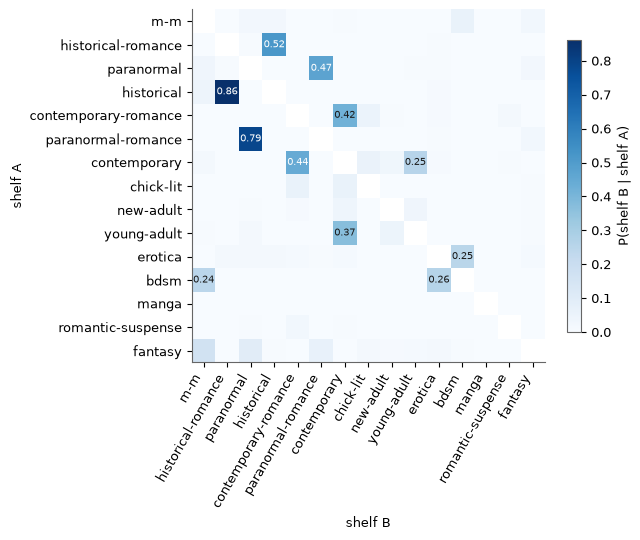

In [26]:
co = Y[tr].T @ Y[tr]
cond = co / np.diag(co)[:, None]
np.fill_diagonal(cond, np.nan)  # diagonal is 1 by definition and would set the color scale
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cond, cmap='Blues', vmin=0)
for i, j in zip(*np.nonzero(np.nan_to_num(cond) >= 0.2)):
    ax.text(j, i, f'{cond[i, j]:.2f}', ha='center', va='center', fontsize=7,
            color='white' if cond[i, j] > 0.5 * np.nanmax(cond) else '#191919')
ax.set(xticks=range(K), yticks=range(K), xlabel='shelf B', ylabel='shelf A')
ax.set_xticklabels(SHELVES, rotation=60, ha='right')
ax.set_yticklabels(SHELVES)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='P(shelf B | shelf A)')
save(3)

*Fig. 3. Co-occurrence of shelves among training books. Each cell gives the fraction of books labeled with the row shelf (A) that also carry the column shelf (B); values of 0.2 or more are printed, and the diagonal is left blank.*

After filtering, 299,789 books remained: 191,692 for training, 47,687 for validation, and 60,410 for testing. The labels are sparse. Of all books, 65.6% carry none of the 15 shelves; the most frequent shelf, `m-m`, applies to 6.8% of training books and the least frequent, `fantasy`, to 1.1%. Shelf frequencies are nearly identical across the three sets (Fig. 2), so the split does not shift the label distribution.

Several of the 15 shelves are near-synonyms, such as `historical` and `historical-romance`, because readers use both names, and such pairs co-occur on many books (Fig. 3). They are kept as separate labels because they are separate shelves on Goodreads, but this overlap is one reason to expect some labels to be unreliable.

### D. Label Noise

A fixed threshold of 10% imposes a hard boundary on what is a continuous vote share. A book that receives 9% of its votes as `contemporary` is labeled negative, and one that receives 11% is labeled positive, although readers treated the two books almost identically. When many books lie just below the boundary, the labels of that shelf are unstable. We quantify this effect for each shelf as the ratio of training books just below the threshold, with 5% to 10% of their votes, to books at or above it. A ratio near zero indicates that readers agree on which books belong to the shelf, and a high ratio indicates that many books divide their readers. The lower edge of 5%, half the threshold, was fixed before any model was trained and was not adjusted afterwards. A different band would change the exact values, so the ratio is used only to rank shelves by how contested their labels are.

In [27]:
near = ((share[tr] >= 0.05) & (share[tr] < MIN_FRAC)).sum(0) / Y[tr].sum(0)
pd.Series(near, index=SHELVES).sort_values().round(2)

manga                   0.03
m-m                     0.43
historical-romance      0.46
young-adult             0.78
chick-lit               1.03
historical              1.12
bdsm                    1.15
romantic-suspense       1.30
new-adult               1.33
paranormal              1.43
paranormal-romance      1.61
erotica                 2.78
fantasy                 3.30
contemporary-romance    3.61
contemporary            5.51
dtype: float64

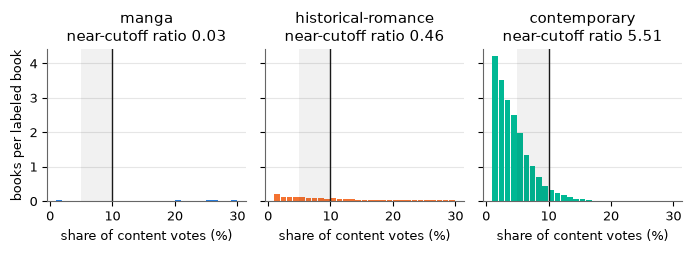

In [28]:
focus = [s for s in FOCUS if s in SHELVES]
fig, axes = plt.subplots(1, len(focus), figsize=(7, 2.6), sharex=True, sharey=True, squeeze=False)
bins = np.arange(0.01, 0.305, 0.01)
for ax, s in zip(axes[0], focus):
    j = SHELVES.index(s)
    counts, _ = np.histogram(share[tr][:, j], bins=bins)
    ax.bar(100 * bins[:-1], counts / Y[tr][:, j].sum(), width=0.9, align='edge', color=FOCUS[s])
    ax.axvspan(5, 10, color='#191919', alpha=0.06, linewidth=0)
    ax.axvline(10, color='#191919', linewidth=1)
    ax.set(title=f'{s}\nnear-cutoff ratio {near[j]:.2f}', xlabel='share of content votes (%)')
    ax.grid(axis='x', visible=False)
axes[0][0].set_ylabel('books per labeled book')
save(4)

*Fig. 4. Distribution of a shelf's share of a book's content votes among training books, for the three focus shelves. Bars are one percentage point wide and are divided by the number of books labeled with the shelf. The vertical line marks the 10% threshold, and the shaded band marks the 5% to 10% range used in the near-cutoff ratio.*

The ratios span two orders of magnitude. For `manga` the ratio is 0.03, since readers either shelve a book as manga or do not. For `contemporary` it is 5.51, meaning that for every book labeled `contemporary` about five more lie just below the threshold and are labeled negative. `contemporary-romance` (3.61), `fantasy` (3.30), and `erotica` (2.78) follow. We hypothesize that the shelves with high ratios will be the most difficult to predict regardless of the model, because their labels depend in part on where an arbitrary boundary falls.

## IV. Model

### A. Formulation

The task is formulated as 15 independent binary classification problems over a shared representation of the text. For shelf $j$ and a book with feature vector $x$, the model computes the score

$$s_j(x) = w_j^\top x + b_j \tag{1}$$

and predicts the shelf when $s_j(x)$ exceeds a threshold $t_j$. Treating the shelves independently ignores correlations between them, such as the overlap between `historical` and `historical-romance`, but keeps the model simple to train and to interpret.

### B. Evaluation Procedure and Baselines

The code below implements the evaluation and the two baselines, which require no training. The function `best_cutoff` selects, for one shelf, the threshold that maximizes F1 on the validation set by scanning every distinct score. The function `scores` computes the metrics of Section II-C on the test set.

In [29]:
def best_cutoff(y, s):
    """Score cutoff with the highest F1 on these labels."""
    order = np.argsort(-s, kind='stable')
    tp = np.cumsum(y[order])
    f1 = 2 * tp / (np.arange(1, len(y) + 1) + y.sum())
    return s[order][np.argmax(f1)]


def scores(y, s, cut):
    p = s >= cut
    return {'micro_f1': f1_score(y, p, average='micro', zero_division=0),
            'macro_f1': f1_score(y, p, average='macro', zero_division=0),
            'macro_auc': roc_auc_score(y, s, average='macro'),
            'macro_ap': average_precision_score(y, s, average='macro'),
            'labels_per_book': p.sum(1).mean()}


results = {}

In [30]:
prior = Y[tr].mean(0)
results['label prior'] = scores(Y[te], np.tile(prior, (len(te), 1)), 0.5)

In [31]:
results['every shelf'] = scores(Y[te], np.ones((len(te), K)), 0.5)

In [32]:
def keyword(texts):
    norm = [' ' + re.sub(r'[^\w]+', ' ', t.lower()) + ' ' for t in texts]
    return np.array([[' ' + s.replace('-', ' ') + ' ' in t for s in SHELVES] for t in norm], dtype=float)

KW_te = keyword(elig['description'].iloc[te])
results['shelf name in text'] = scores(Y[te], KW_te, 0.5)

### C. Text Representation

Each description is represented by TF-IDF features. The term frequency counts the occurrences of a term in a description, and the inverse document frequency down-weights terms that occur in many descriptions. Terms that occur in nearly every romance description, such as "love" or "life", therefore contribute little, while distinctive terms such as "duke" or "vampire" contribute more. Two kinds of terms are used. Word unigrams and bigrams (50,000 features, English stop words removed) capture topical vocabulary and multi-word names such as series titles. Character 3- to 5-grams (60,000 features, weighted by 0.5) capture fragments of words, which help with names, inflected forms, and descriptions in other languages. Both vectorizers were fit on the training descriptions only. The vocabulary sizes, the minimum document frequency of 5, and the weight on character features were fixed in our group's earlier experiments and were not tuned here. A description contains many more distinct character sequences than words, and the weight of 0.5 prevents the character features from dominating the word features.

This representation assumes that genre is expressed by which terms occur, independent of their order. The assumption is reasonable for genres with a characteristic vocabulary, but the representation cannot capture meaning that depends on word order or information that a description omits.

In [33]:
word = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), min_df=5, stop_words='english',
                       sublinear_tf=True, dtype=np.float32)
char = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=5, max_features=60_000,
                       sublinear_tf=True, dtype=np.float32)
text = elig['description']
word.fit(text.iloc[tr])
char.fit(text.iloc[tr])


def features(idx):
    return hstack([word.transform(text.iloc[idx]), 0.5 * char.transform(text.iloc[idx])]).tocsr()


X_tr, X_va, X_te = features(tr), features(va), features(te)
FEATURES = np.r_[word.get_feature_names_out(), char.get_feature_names_out()]
print(X_tr.shape, f'{X_tr.nnz / X_tr.shape[0]:.0f} nonzero features per book')

(191692, 110000) 1236 nonzero features per book


### D. Classifier

One logistic regression per shelf was trained, implemented in PyTorch as a single linear layer with 15 outputs so that it runs on a GPU. The loss is the binary cross-entropy over all shelves plus an $L_2$ penalty on the weights; it equals the objective of scikit-learn's `LogisticRegression(C=1, class_weight='balanced')` divided by the number of training books. Balanced class weights scale the loss of positive examples in proportion to their rarity. Without them, the model could attain a low loss by predicting no shelves, since 97% of the targets are negative. Optimization used Adam with a learning rate of 0.01 on mini-batches of 4,096 books for 8 epochs. These settings were chosen for speed and memory and were not tuned. Each book uses about 1,200 of the 110,000 features, so the feature matrix is stored in sparse form, which fits in the 8 GB memory of a laptop GPU.

### E. Model Selection

Logistic regression on TF-IDF features was chosen because it is an established baseline for text classification [3], it is part of the course material, it trains in minutes on 190,000 documents, and its weights can be inspected directly, which Section V-D uses to check the evidence the model relies on. In earlier experiments, our group compared eight scikit-learn configurations by validation macro-F1. The configurations varied the features (words only, or words and characters), the regularization strength ($C \in \{0.25, 1, 4\}$), class weighting, and the classifier (logistic regression or a linear SVM). Logistic regression with word and character features and $C = 1$ performed best and is the configuration used here. Models that use word order, such as fine-tuned transformers, may capture more of a description's meaning, but they are considerably more expensive to train on this corpus and were not evaluated.

In [34]:
# Same objective as sklearn's LogisticRegression(C=1, class_weight='balanced'), divided by n:
# mean weighted log-loss + ||W||^2 / (2 C n). Mini-batches keep memory small on an 8 GB card.
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.sparse.check_sparse_tensor_invariants.disable()  # explicit opt-out; checks cost time, our indices come from scipy


def to_torch(x):
    x = x.tocoo()
    i = torch.from_numpy(np.vstack([x.row, x.col]).astype(np.int64))
    return torch.sparse_coo_tensor(i, torch.from_numpy(x.data), x.shape).to(DEV)


def fit_lr(x, y, x_va, y_va, C=1.0, epochs=8, batch=4096, lr=0.01, seed=0):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    n = len(y)
    yt = torch.from_numpy(y).to(DEV)
    pos = yt.sum(0)
    w_pos, w_neg = n / (2 * pos), n / (2 * (n - pos))  # class_weight='balanced'
    W = torch.zeros(x.shape[1], y.shape[1], device=DEV, requires_grad=True)
    b = torch.zeros(y.shape[1], device=DEV, requires_grad=True)
    opt = torch.optim.Adam([W, b], lr=lr)
    yv = torch.from_numpy(y_va)
    hist = []
    for epoch in range(epochs):
        total = 0.0
        for idx in np.array_split(rng.permutation(n), max(n // batch, 1)):
            yb = yt[idx]
            logits = torch.sparse.mm(to_torch(x[idx]), W) + b
            loss = torch.nn.functional.binary_cross_entropy_with_logits(
                logits, yb, weight=yb * w_pos + (1 - yb) * w_neg)
            loss = loss + (W ** 2).sum() / (2 * C * n)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        # validation: same class weights, no penalty
        val = torch.nn.functional.binary_cross_entropy_with_logits(
            torch.from_numpy(decision(x_va, W.detach(), b.detach())), yv,
            weight=yv * w_pos.cpu() + (1 - yv) * w_neg.cpu()).item()
        hist.append((total / n, val))
        print(f'epoch {epoch + 1}: train objective {total / n:.4f}, validation log-loss {val:.4f}')
    return W.detach(), b.detach(), hist


@torch.no_grad()
def decision(x, W, b, batch=8192):
    out = [(torch.sparse.mm(to_torch(x[i:i + batch]), W) + b).cpu().numpy() for i in range(0, x.shape[0], batch)]
    return np.vstack(out)


W, b, hist = fit_lr(X_tr, Y[tr], X_va, Y[va])
S_va, S_te = decision(X_va, W, b), decision(X_te, W, b)

epoch 1: train objective 0.5337, validation log-loss 0.4303
epoch 2: train objective 0.4107, validation log-loss 0.3935
epoch 3: train objective 0.3831, validation log-loss 0.3797
epoch 4: train objective 0.3698, validation log-loss 0.3709
epoch 5: train objective 0.3620, validation log-loss 0.3657
epoch 6: train objective 0.3571, validation log-loss 0.3636
epoch 7: train objective 0.3538, validation log-loss 0.3608
epoch 8: train objective 0.3515, validation log-loss 0.3574


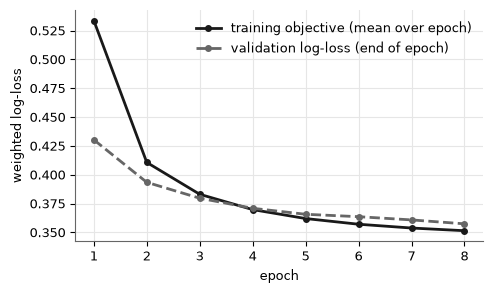

In [35]:
h = np.array(hist)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(ep, h[:, 0], color='#191919', linewidth=2, marker='o', markersize=4,
        label='training objective (mean over epoch)')
ax.plot(ep, h[:, 1], color='#666666', linewidth=2, linestyle='--', marker='o', markersize=4,
        label='validation log-loss (end of epoch)')
ax.set(xlabel='epoch', ylabel='weighted log-loss', xticks=ep)
ax.legend(frameon=False)
save(5)

*Fig. 5. Training objective, averaged over the mini-batches of each epoch and including the $L_2$ penalty, and weighted log-loss on the validation set at the end of each epoch.*

### F. Convergence

The training loss was still decreasing at the eighth epoch (Fig. 5), so the model had not fully converged. In our group's earlier experiments, scikit-learn's solver fit the same objective to convergence and reached a test macro-F1 of 0.484, compared with 0.454 here. The results in Section V are therefore a slight underestimate of what this model can achieve, and the untuned optimizer settings are the most likely source of the difference.

## V. Evaluation

### A. Overall Results

The threshold of each shelf was selected on the validation set, and every model was evaluated once on the test set. To measure the contribution of the character features, the same model was also trained on the word features alone, with its own thresholds. The uncertainty of each score was estimated with 1,000 bootstrap resamples of the test set. Works were resampled instead of books, since editions of one work share a description and are not independent.

In [36]:
cut = np.array([best_cutoff(Y[va][:, j], S_va[:, j]) for j in range(K)])
results['model, cutoff 0'] = scores(Y[te], S_te, 0.0)
results['model, cutoff per shelf'] = scores(Y[te], S_te, cut)

In [37]:
nw = len(word.vocabulary_)
W_w, b_w, _ = fit_lr(X_tr[:, :nw], Y[tr], X_va[:, :nw], Y[va])
S_va_w, S_te_w = decision(X_va[:, :nw], W_w, b_w), decision(X_te[:, :nw], W_w, b_w)
cut_w = np.array([best_cutoff(Y[va][:, j], S_va_w[:, j]) for j in range(K)])
results['model, words only'] = scores(Y[te], S_te_w, cut_w)
pd.DataFrame(results).T.round(3)

epoch 1: train objective 0.5955, validation log-loss 0.5175
epoch 2: train objective 0.4780, validation log-loss 0.4644
epoch 3: train objective 0.4370, validation log-loss 0.4379
epoch 4: train objective 0.4163, validation log-loss 0.4219
epoch 5: train objective 0.4043, validation log-loss 0.4115
epoch 6: train objective 0.3965, validation log-loss 0.4046
epoch 7: train objective 0.3912, validation log-loss 0.3983
epoch 8: train objective 0.3874, validation log-loss 0.3945


,micro_f1,macro_f1,macro_auc,macro_ap,labels_per_book
label prior,0.000,0.000,0.500,0.029,0.000
every shelf,0.057,0.056,0.500,0.029,15.000
shelf name in text,0.108,0.106,0.536,0.051,0.148
"model, cutoff 0",0.350,0.341,0.933,0.397,1.588
"model, cutoff per shelf",0.480,0.454,0.933,0.397,0.611
"model, words only",0.453,0.425,0.924,0.372,0.592


In [38]:
systems = {'label prior': np.zeros((len(te), K), bool), 'every shelf': np.ones((len(te), K), bool),
           'shelf name in text': KW_te >= 0.5, 'model, cutoff 0': S_te >= 0.0,
           'model, words only': S_te_w >= cut_w, 'model, cutoff per shelf': S_te >= cut}
Yt = Y[te].astype(bool)
g = pd.factorize(elig['group'].iloc[te])[0]
G = csr_matrix((np.ones(len(te), np.float32), (g, np.arange(len(te)))))
# per work and shelf: true positives, false positives, false negatives of every system
counts = np.hstack([G @ np.hstack([Yt & p, ~Yt & p, Yt & ~p]).astype(np.float32) for p in systems.values()])


def macro_f1(c):
    c = c.reshape(*c.shape[:-1], len(systems), 3, K)
    tp, fp, fn = c[..., 0, :], c[..., 1, :], c[..., 2, :]
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0).mean(-1)


point = macro_f1(counts.sum(0))
for k, name in enumerate(systems):
    assert np.isclose(point[k], results[name]['macro_f1'], atol=1e-6), name
rng = np.random.default_rng(0)
n_works = G.shape[0]
boot = np.array([macro_f1(np.bincount(rng.integers(0, n_works, n_works), minlength=n_works) @ counts)
                 for _ in range(1000)])
names = list(systems)
ci = pd.DataFrame({'macro_f1': point, 'low': np.percentile(boot, 2.5, 0), 'high': np.percentile(boot, 97.5, 0)},
                  index=names)
best = names.index('model, cutoff per shelf')
for other in ['model, cutoff 0', 'shelf name in text', 'model, words only']:
    diff = boot[:, best] - boot[:, names.index(other)]
    ci.loc[f'difference: cutoff per shelf - {other}'] = [point[best] - point[names.index(other)],
                                                         *np.percentile(diff, [2.5, 97.5])]
print(f'{n_works} test works, 1000 resamples')
ci.round(3)

32934 test works, 1000 resamples


,macro_f1,low,high
label prior,0.000,0.000,0.000
every shelf,0.056,0.054,0.058
shelf name in text,0.106,0.099,0.113
"model, cutoff 0",0.341,0.332,0.349
"model, words only",0.425,0.413,0.436
"model, cutoff per shelf",0.454,0.443,0.464
"difference: cutoff per shelf - model, cutoff 0",0.113,0.105,0.121
difference: cutoff per shelf - shelf name in text,0.348,0.335,0.360
"difference: cutoff per shelf - model, words only",0.029,0.025,0.033


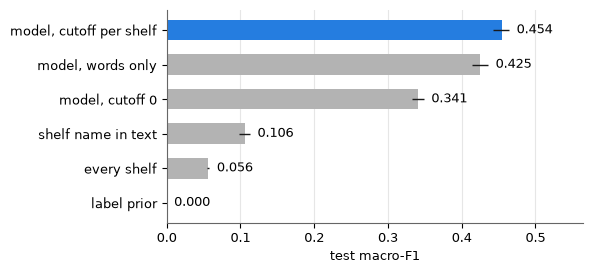

In [39]:
c6 = ci.loc[names].sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(c6.index, c6['macro_f1'], height=0.6,
        color=['#257de0' if n == 'model, cutoff per shelf' else GRAY for n in c6.index],
        xerr=[c6['macro_f1'] - c6['low'], c6['high'] - c6['macro_f1']], error_kw={'ecolor': '#191919', 'lw': 1})
for i, v in enumerate(c6['macro_f1']):
    ax.text(c6['high'].iloc[i] + 0.01, i, f'{v:.3f}', va='center')
ax.set(xlabel='test macro-F1', xlim=(0, max(c6['high']) + 0.1))
ax.grid(axis='y', visible=False)
save(6)

*Fig. 6. Macro-F1 on the test set for each baseline and model. Error bars are 95% percentile intervals from 1,000 bootstrap resamples of test works, with the thresholds held fixed; they reflect sampling of the test set only, not variation between training runs.*

The description carries substantial information about a book's shelves, well beyond what a keyword rule extracts. The label prior scores zero, as expected. The keyword baseline reaches a macro-F1 of only 0.106, because reader-defined shelf names rarely occur in publisher descriptions; a book shelved as `contemporary` seldom describes itself as contemporary. The learned model reaches a macro-F1 of 0.454 and a micro-F1 of 0.480, more than four times the keyword baseline.

Threshold selection contributes as much as the learned weights. At the default threshold of 0.5, the balanced class weights make the model over-predict: it assigns 1.59 shelves per book, whereas books carry about 0.44 on average, and its macro-F1 is 0.341. Thresholds selected on the validation set reduce the rate to 0.61 shelves per book and raise macro-F1 to 0.454. AUC is independent of the threshold and is therefore identical in both rows.

The difference between AUC and AP characterizes the remaining errors. An AUC of 0.933 means that, averaged over shelves, a randomly chosen book that carries a shelf receives a higher score than a randomly chosen book that does not about 93% of the time; the ranking is good. AP, at 0.397, reflects the precision among the highest-ranked books and is much lower because positives are rare. A small error rate on the large number of negative books suffices to place many false positives at the top of the ranking.

In [40]:
P = S_te >= cut
per_shelf = pd.DataFrame({
    'test_positives': Y[te].sum(0).astype(int),
    'f1': f1_score(Y[te], P, average=None, zero_division=0),
    'precision': precision_score(Y[te], P, average=None, zero_division=0),
    'recall': recall_score(Y[te], P, average=None, zero_division=0),
    'auc': [roc_auc_score(Y[te][:, j], S_te[:, j]) for j in range(K)],
    'keyword_f1': f1_score(Y[te], KW_te >= 0.5, average=None, zero_division=0),
    'near_cutoff_ratio': near,
}, index=SHELVES)
per_shelf.sort_values('f1').round(3)

,test_positives,f1,precision,recall,auc,keyword_f1,near_cutoff_ratio
contemporary,1833,0.244,0.190,0.343,0.834,0.036,5.507
contemporary-romance,1635,0.279,0.241,0.330,0.859,0.043,3.608
erotica,983,0.308,0.232,0.459,0.915,0.121,2.781
fantasy,625,0.328,0.357,0.302,0.933,0.059,3.302
new-adult,1549,0.339,0.382,0.304,0.921,0.207,1.330
young-adult,1304,0.393,0.336,0.475,0.945,0.036,0.781
romantic-suspense,876,0.401,0.309,0.572,0.954,0.107,1.295
chick-lit,1720,0.422,0.397,0.451,0.928,0.015,1.035
paranormal,2596,0.459,0.358,0.639,0.931,0.158,1.425
paranormal-romance,1494,0.460,0.374,0.598,0.946,0.079,1.611


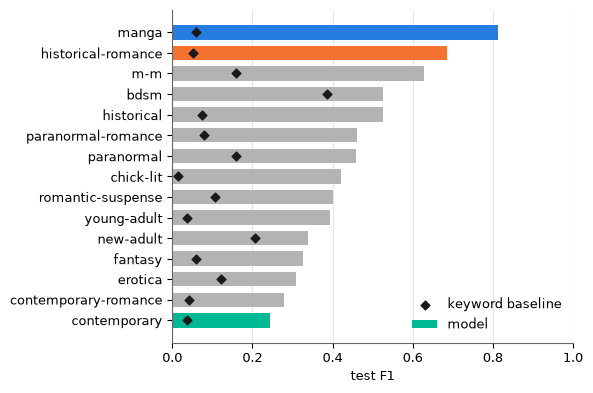

In [41]:
order = per_shelf.sort_values('f1').index
y = np.arange(K)
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(y, per_shelf.loc[order, 'f1'], height=0.7, color=[color(s) for s in order], label='model')
ax.scatter(per_shelf.loc[order, 'keyword_f1'], y, marker='D', s=20, color='#191919', label='keyword baseline')
ax.set(yticks=y, yticklabels=order, xlabel='test F1', xlim=(0, 1))
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right', frameon=False)
save(7)

*Fig. 7. Test F1 of the model for each shelf (bars) and of the keyword baseline (diamonds), with shelves ordered by model F1.*

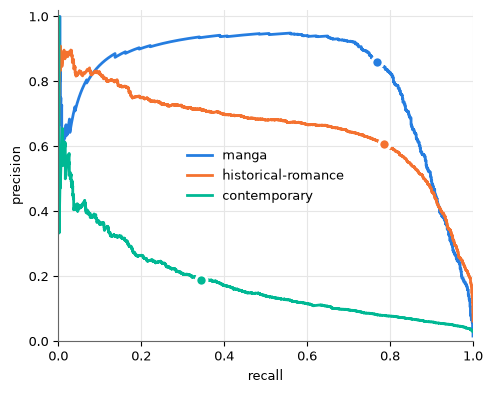

In [42]:
fig, ax = plt.subplots(figsize=(5, 4))
for s in focus:
    j = SHELVES.index(s)
    prec, rec, _ = precision_recall_curve(Y[te][:, j], S_te[:, j])
    ax.plot(rec, prec, color=FOCUS[s], linewidth=2, label=s)
    ax.plot(per_shelf.loc[s, 'recall'], per_shelf.loc[s, 'precision'], 'o', markersize=8, color=FOCUS[s],
            markeredgecolor='white', markeredgewidth=2)
ax.set(xlabel='recall', ylabel='precision', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(frameon=False)
save(8)

*Fig. 8. Precision-recall curves on the test set for the three focus shelves. The dot on each curve marks the precision and recall at the threshold selected on the validation set.*

### B. Per-Shelf Results

The average conceals large differences between shelves (Fig. 7). `manga` reaches an F1 of 0.812, with a precision of 0.86 and a recall of 0.77. `historical-romance` (0.685) and `m-m` (0.627) also perform well. At the other extreme, `contemporary` reaches an F1 of 0.244 with a precision of 0.19, and `contemporary-romance` reaches 0.279. These two shelves also have the lowest AUC (0.834 and 0.859). A low AUC indicates that the model fails to separate their books from the rest even in its ranking, so no choice of threshold can correct them (Fig. 8).

The per-shelf results thus give a qualified answer to the research question. For shelves with a distinctive vocabulary, the description predicts the shelf with useful precision and recall; for shelves such as `contemporary`, it largely does not. The next analysis examines the cause.

In [43]:
rho_noise, p_noise = spearmanr(per_shelf['near_cutoff_ratio'], per_shelf['f1'])
rho_count, p_count = spearmanr(per_shelf['test_positives'], per_shelf['f1'])
print(f'Spearman with F1 (n = {K} shelves): near-cutoff ratio {rho_noise:+.2f} (p = {p_noise:.3f}), '
      f'test positives {rho_count:+.2f} (p = {p_count:.3f})')
# other lower edges of the band, to check that the result does not depend on the 5% choice
for lo in (0.025, 0.05, 0.075):
    r = ((share[tr] >= lo) & (share[tr] < MIN_FRAC)).sum(0) / Y[tr].sum(0)
    rho, p = spearmanr(r, per_shelf['f1'])
    print(f'band {lo:.1%} to {MIN_FRAC:.0%}: rho {rho:+.2f} (p = {p:.3f})')

Spearman with F1 (n = 15 shelves): near-cutoff ratio -0.82 (p = 0.000), test positives +0.23 (p = 0.413)
band 2.5% to 10%: rho -0.87 (p = 0.000)
band 5.0% to 10%: rho -0.82 (p = 0.000)
band 7.5% to 10%: rho -0.83 (p = 0.000)


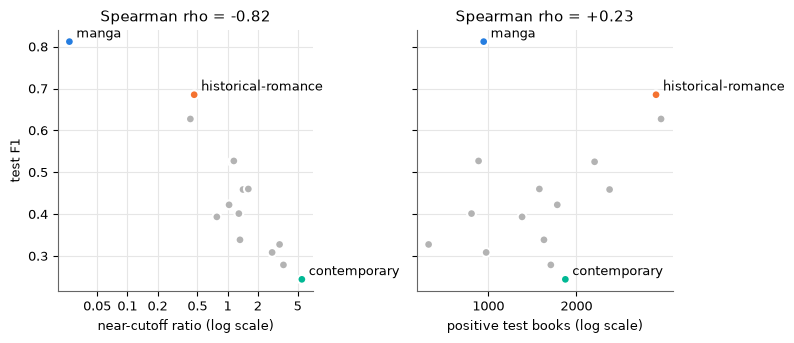

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)
for ax, col, xlabel, rho in [(axes[0], 'near_cutoff_ratio', 'near-cutoff ratio (log scale)', rho_noise),
                             (axes[1], 'test_positives', 'positive test books (log scale)', rho_count)]:
    ax.scatter(per_shelf[col], per_shelf['f1'], s=40, c=[color(s) for s in SHELVES],
               edgecolors='white', linewidths=1.5, zorder=3)
    for s in focus:  # labels on all 15 collide; the per-shelf table gives the rest
        ax.annotate(s, (per_shelf.loc[s, col], per_shelf.loc[s, 'f1']), xytext=(5, 3), textcoords='offset points')
    ax.set(xscale='log', xlabel=xlabel, title=f'Spearman rho = {rho:+.2f}')
    ax.minorticks_off()
    ax.xaxis.set_major_locator(plt.LogLocator(subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(plt.FormatStrFormatter('%g'))
axes[0].set_ylabel('test F1')
save(9)

*Fig. 9. Test F1 of each shelf against its near-cutoff ratio (left) and against its number of positive test books (right), both on logarithmic axes. Each point is one shelf, and the three focus shelves are labeled; the panel titles give Spearman's rank correlation over the 15 shelves.*

### C. Label Noise and Performance

The hypothesis of Section III-D was tested by comparing each shelf's label-noise ratio with its test F1 (Fig. 9). Spearman's rank correlation was used because only 15 shelves are available, the ratio is heavily skewed (from 0.03 to 5.51), and the question is whether noisier shelves score lower, irrespective of the functional form of the relationship. The correlation is $\rho = -0.82$: the shelves on which readers disagree most are those the model predicts worst. The number of positive test books is only weakly related to F1 ($\rho = +0.23$), so the weak shelves are not weak merely because they are small. For example, `contemporary` and `historical` have a similar number of positive test books (1,833 and 2,307), yet their F1 scores are 0.244 and 0.525.

These results suggest that the performance ceiling on these shelves is set mainly by the labels. If readers do not agree on whether a book is `contemporary`, a classifier trained to reproduce their votes inherits that disagreement. With 15 shelves, the correlation is suggestive rather than conclusive, and it does not exclude other explanations, such as the absence of a distinctive vocabulary discussed next.

A direct test of the hypothesis rescored each shelf after removing the test books whose share for that shelf lies just below the threshold, between 5% and 10%. All of these books are negatives, so their removal raises precision by construction, even if the books are no harder than other negatives. As a control, the same number of randomly chosen negatives outside the band was removed instead, 20 times per shelf. The effect of the band is the difference between the two scores.

In [45]:
band = (share[te] >= 0.05) & (share[te] < MIN_FRAC)
rng = np.random.default_rng(0)
rows = []
for j, s in enumerate(SHELVES):
    neg = np.flatnonzero(~Yt[:, j] & ~band[:, j])
    control = []
    for _ in range(20):
        keep = np.ones(len(te), bool)
        keep[rng.choice(neg, band[:, j].sum(), replace=False)] = False
        control.append(f1_score(Yt[keep, j], P[keep, j], zero_division=0))
    rows.append({'band_books': band[:, j].sum(), 'f1_all': per_shelf.loc[s, 'f1'],
                 'f1_random_negatives_dropped': np.mean(control),
                 'f1_band_dropped': f1_score(Yt[~band[:, j], j], P[~band[:, j], j], zero_division=0)})
clean = pd.DataFrame(rows, index=SHELVES)
clean['band_effect'] = clean['f1_band_dropped'] - clean['f1_random_negatives_dropped']
clean.loc[order].round(3)

,band_books,f1_all,f1_random_negatives_dropped,f1_band_dropped,band_effect
contemporary,9110,0.244,0.259,0.314,0.055
contemporary-romance,6401,0.279,0.287,0.348,0.061
erotica,2887,0.308,0.313,0.390,0.077
fantasy,2050,0.328,0.330,0.372,0.042
new-adult,1706,0.339,0.340,0.370,0.029
young-adult,1102,0.393,0.396,0.429,0.033
romantic-suspense,1179,0.401,0.404,0.471,0.067
chick-lit,1598,0.422,0.425,0.465,0.040
paranormal,4055,0.459,0.465,0.600,0.135
paranormal-romance,2571,0.460,0.465,0.556,0.091


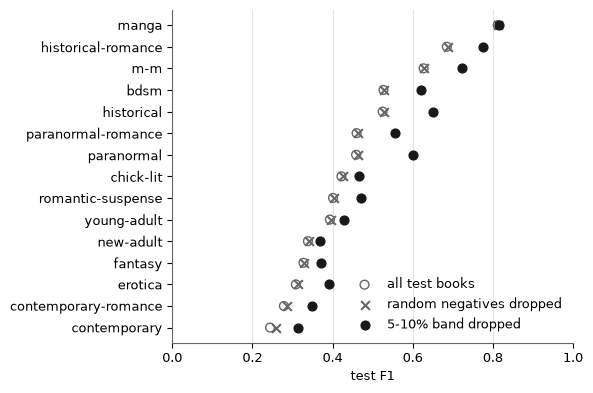

In [46]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(clean.loc[order, 'f1_all'], y, s=40, facecolors='none', edgecolors='#666666', label='all test books')
ax.scatter(clean.loc[order, 'f1_random_negatives_dropped'], y, s=40, marker='x', color='#666666',
           label='random negatives dropped')
ax.scatter(clean.loc[order, 'f1_band_dropped'], y, s=40, color='#191919', label='5-10% band dropped')
ax.set(yticks=y, yticklabels=order, xlabel='test F1', xlim=(0, 1))
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right', frameon=False)
save(10)

*Fig. 10. Test F1 per shelf on all test books (circles), after removing a random set of negatives (crosses), and after removing the negatives in the 5% to 10% band of the shelf (dots). Both removals drop the same number of books. Shelves are ordered as in Fig. 7.*

In [47]:
Wn = W.cpu().numpy()
top = pd.DataFrame([FEATURES[np.argsort(-Wn[:, j])[:8]] for j in range(K)], index=SHELVES)
print(top.to_string(header=False))

m-m                            gay     his       his      man      lover         men        his            he 
historical-romance            lady     earl     lord     duke     london  historical    viscount         marry
paranormal              paranormal     mate  vampire  psychic    shifter       demon        vamp           vam
historical                    lady   london     earl     lord       duke         war  historical      viscount
contemporary-romance  virgin river     sexy    idaho    river  fool gold     gansett        town         susan
paranormal-romance         vampire     vamp      vam     vamp        vam       vampi       ampir         demon
contemporary                  lucy      dad      guy    idaho     walker          .        maybe  lucky harbor
chick-lit                       -     holly    novel  bridget  boyfriend      mother   hilarious           job
new-adult                new adult  college     girl    adult     campus  university      hardin           guy
y

### D. Learned Features

The output above lists the eight terms with the largest positive weight for each shelf. For the well-predicted shelves, these are the terms a human reader would expect: `historical-romance` relies on *lady*, *earl*, *lord*, and *duke*; `bdsm` on *dom*, *master*, and *submissive*; `manga` on the word *manga* and fragments of Japanese names; and `m-m` on *gay* and male pronouns. The model therefore bases its predictions for these shelves on genre evidence, which supports their validity.

For `contemporary` and `contemporary-romance`, the strongest terms are names of particular series and places, such as *Virgin River*, *Idaho*, and *Lucky Harbor*. We hypothesize that contemporary romance has little vocabulary of its own, because it is defined mainly by the absence of other markers, namely a present-day setting without historical or supernatural elements. The weights are consistent with this hypothesis, since the model's strongest evidence for these shelves consists of popular series, which cannot generalize to a standalone novel; the hypothesis was not tested directly. A few character-level features, such as single punctuation marks, also rank among the top terms. They may reflect the formatting conventions of particular publishers, which was not verified.

In [48]:
margin = S_te - cut
info = elig.iloc[te].reset_index(drop=True)


def errors(mask, sign):
    i, j = np.nonzero(mask)
    k = np.argsort(sign * margin[i, j])[:10]
    return pd.DataFrame({'shelf': np.array(SHELVES)[j[k]], 'vote_share': share[te][i[k], j[k]].round(3),
                         'content_votes': info['sh_votes'].iloc[i[k]].values,
                         'margin': margin[i[k], j[k]].round(2), 'title': info['title'].iloc[i[k]].values,
                         'description': info['description'].iloc[i[k]].str.replace(r'\s+', ' ', regex=True).str.slice(0, 150).values})


with pd.option_context('display.max_colwidth', 150, 'display.width', 250):
    print('false positives\n', errors(~Yt & P, -1).to_string(index=False))
    print('\nfalse negatives\n', errors(Yt & ~P, 1).to_string(index=False))

false positives
              shelf  vote_share  content_votes  margin                                                             title                                                                                                                                            description
              bdsm       0.051             78    5.10                 The Mistress Files: The Case of the Diffident Dom Welcome to the private files of Nora Sutherlin, The Mistress. Kingsley Edge, owner of the 8th Circle BDSM club, has ordered her to compose client prof
              bdsm       0.050             20    4.79                                                            To Sir When Elizabeth Clark is plagued by the idea for a kinky novel she can't shake, she has no choice but to plunge, head-first into a genre she vowed neve
historical-romance       0.097             31    4.72 A Taste of Scandal: Regency Rogues, Bad Boys, and Sexy Scoundrels Heat up your history with these eight amazing nove

### E. Error Analysis

In an earlier run of the same kind of model, our group examined ten of the most confident errors together with their descriptions and vote counts. Most were not failures to interpret the text. In some cases, readers had split their votes across spellings (`manga`, `mangas`, `manga-manhwa`), so the exact shelf remained below 10% even though the description matched it. In others, a sibling shelf such as `contemporary-romance` was positive while `contemporary` fell just below the threshold, or the label rested on two to five votes for a book whose description concerned something else. Three of the ten errors were cases in which the description did not mention the relevant fact, such as a manga volume whose stored description is a prose plot summary. Because the ten examples were selected for high confidence, they indicate which kinds of errors occur but not their frequency.

### F. Limitations

The labels are a single, unverified snapshot of reader votes, so measured performance is bounded by their quality. The evaluated books already have at least 10 genre votes and are more established than a typical new release. The model ignores correlations between shelves, and near-duplicate shelves are kept separate. In the earlier run, merging the three pairs of near-duplicate shelves into 12 labels raised the scores, but this changes the task to an easier one and does not indicate a better model. Finally, the optimizer settings were not tuned and the model had not converged (Section IV-F).

## VI. Related Work

The dataset was introduced by Wan and McAuley [1], who used Goodreads interactions to study recommendation when a user's actions form a monotonic chain of shelving, reading, rating, and recommending a book. Their models learn from users' past interactions with each item, which a newly released book lacks. The present work addresses the complementary, item-side problem of characterizing a new book from its own content. Wan et al. [2] used reviews from the same crawl for fine-grained spoiler detection, a classification task on review sentences. The romance file contains descriptions and no reviews, so a direct comparison with that task is not possible.

Wang and Manning [3] showed that linear classifiers over word unigrams and bigrams, such as naive Bayes and linear support vector machines, are strong baselines for sentiment and topic classification, and that bigrams improve performance. Our results are consistent with theirs: a linear model over TF-IDF features performs well above trivial baselines, and in our group's earlier experiments, adding character n-grams to word features raised macro-F1 by 0.022. Wang and Manning also note that bag-of-words models cannot capture meaning arising from the composition of words. Our error analysis indicates a different limitation, namely that many errors originate in the labels or in information absent from the description, which no model of the text can recover.

We are not aware of published results for shelf prediction on this dataset, so our F1 scores cannot be compared with prior work directly; the baselines of Section II-D serve as the points of comparison.

## VII. Conclusion

Given only its description, a TF-IDF model predicts a romance book's shelves well when the shelf corresponds to a distinctive vocabulary, as for `manga`, `historical-romance`, and `m-m`, with F1 between 0.63 and 0.81. It predicts poorly when readers apply the shelf inconsistently, as for `contemporary`, with F1 below 0.3. Across all 15 shelves, the model scores more than four times higher than a keyword baseline, and the strongest predictor of where it fails is reader disagreement about the label rather than the amount of training data. For a cold-start system, descriptions are therefore a reliable source of genre tags for some shelves and an unreliable one for others.

## References

[1] M. Wan and J. McAuley, "Item recommendation on monotonic behavior chains," in *Proc. 12th ACM Conf. Recommender Systems (RecSys)*, 2018, pp. 86-94, doi: 10.1145/3240323.3240369.

[2] M. Wan, R. Misra, N. Nakashole, and J. McAuley, "Fine-grained spoiler detection from large-scale review corpora," in *Proc. 57th Annu. Meeting Assoc. Computational Linguistics (ACL)*, 2019, pp. 2605-2610. [Online]. Available: https://aclanthology.org/P19-1248/

[3] S. Wang and C. D. Manning, "Baselines and bigrams: Simple, good sentiment and topic classification," in *Proc. 50th Annu. Meeting Assoc. Computational Linguistics (ACL), Vol. 2: Short Papers*, 2012, pp. 90-94. [Online]. Available: https://aclanthology.org/P12-2018/